# Question 1. Feedforward Neural Networks

## Imports

In [9]:
import tensorflow as tf
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

## a) Load Data

We load the MNIST Handwritten-digits and MNIST Fashion datasets. We report the original training and testing shapes for each dataset.

In [3]:
(x_digits_train, y_digits_train), (x_digits_test, y_digits_test) = tf.keras.datasets.mnist.load_data()
(x_fashion_train, y_fashion_train), (x_fashion_test, y_fashion_test) = tf.keras.datasets.fashion_mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [4]:
shapes = pd.DataFrame({
    "X_train": [x_digits_train.shape, x_fashion_train.shape],
    "y_train": [y_digits_train.shape, y_fashion_train.shape],
    "X_test":  [x_digits_test.shape, x_fashion_test.shape],
    "y_test":  [y_digits_test.shape, y_fashion_test.shape],
}, index=["MNIST Digits", "Fashion MNIST"])

display(shapes)

,X_train,y_train,X_test,y_test
MNIST Digits,"(60000, 28, 28)","(60000,)","(10000, 28, 28)","(10000,)"
Fashion MNIST,"(60000, 28, 28)","(60000,)","(10000, 28, 28)","(10000,)"


Both of the datasets have 60,000 training examples and 10,000 testing examples. For both datasets, each input is a $28 \times 28$ grayscale image. Each pixel is an intensity from 0 to 255. For the handwritten digits dataset, each output corresponds to the integer label 0-9. For the fashion dataset, each output corresponds to an integer class label 0-9, where:
- 0: T-shirt/top
- 1: Trouser
- 2: Pullover
- 3: Dress
- 4: Coat
- 5: Sandal
- 6: Shirt
- 7: Sneaker
- 8: Bag
- 9: Ankle Boot

Each input is three-dimensional because `x` is a stack of 2D images, so its shape is `(n_samples, 28, 28)`. 

Next, we convert Image values to floating point and normalize them to [0,1] by dividing by 255. We keep the supplied test sets unchanged. 

In [5]:
# Convert to float32 and normalize to [0, 1]
x_digits_train = x_digits_train.astype("float32") / 255.0
x_digits_test  = x_digits_test.astype("float32") / 255.0
x_fashion_train = x_fashion_train.astype("float32") / 255.0
x_fashion_test  = x_fashion_test.astype("float32") / 255.0

Next, we divide each supplied training set into fitting and validation sets and report their sizes. `stratify=y_train` keeps the share of each class the same in both parts of the split.

In [8]:
# Split each training set into fitting (80%) and validation (20%) sets
x_digits_fit, x_digits_val, y_digits_fit, y_digits_val = train_test_split(
    x_digits_train, y_digits_train, test_size=0.20, stratify=y_digits_train, random_state=42)
x_fashion_fit, x_fashion_val, y_fashion_fit, y_fashion_val = train_test_split(
    x_fashion_train, y_fashion_train, test_size=0.20, stratify=y_fashion_train, random_state=42)

sizes = pd.DataFrame({
    "Fitting":    [len(x_digits_fit), len(x_fashion_fit)],
    "Validation": [len(x_digits_val), len(x_fashion_val)],
    "Test":       [len(x_digits_test), len(x_fashion_test)],
}, index=["MNIST Digits", "Fashion MNIST"])

display(sizes)

,Fitting,Validation,Test
MNIST Digits,48000,12000,10000
Fashion MNIST,48000,12000,10000


We display the first fitting image and its label for each dataset. `axes = plt.subplots(1,2)` makes one figure split into a grid of 1 row and 2 columns. `axes[0]` is the left panel and `axes[1]` is the right panel. `imshow` draws a 2D array as an image, with each value corresponding to one pixel. `cmap='gray'` maps values from black at 0 to while at 1.

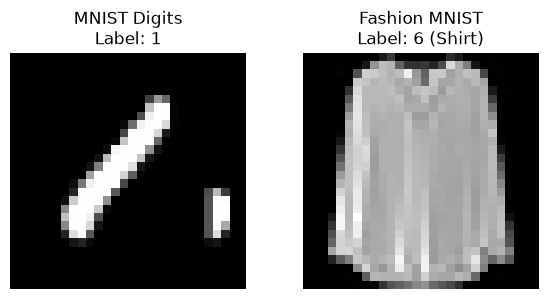

In [11]:
fashion_classes = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig, axes = plt.subplots(1, 2, figsize=(6, 3))

axes[0].imshow(x_digits_fit[0], cmap="gray")
axes[0].set_title(f"MNIST Digits\nLabel: {y_digits_fit[0]}")

axes[1].imshow(x_fashion_fit[0], cmap="gray")
axes[1].set_title(f"Fashion MNIST\nLabel: {y_fashion_fit[0]} ({fashion_classes[y_fashion_fit[0]]})")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## b) Build Simple Model

This function builds a simple neural network for image classification. The input layer takes $28 \times 28$ images. `Flatten` turns each image into a vector of 784 values. The output layer has 10 softmax neurons, one per class. It compiles with `Adam` using `sparce_categorical_crossentropy` and `learning_rate=0.001`. 

In [13]:
def build_simple_model(hidden_units=64, activation='relu', learning_rate=0.001):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(hidden_units, activation=activation),
        tf.keras.layers.Dense(10, activation='softmax'),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

In [14]:
model = build_simple_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Flattening is needed because `Dense` layers expect each input to be a 1-D vector, but each image is a $28 \times 28$ grid. `Flatten` turns the grid into a vector of 784 pixel values to that the hidden layer can connect every pixel to every neuron. 

A 10-neuron output is needed because both datasets have 10 classes, so there's one output neuron per class. Softmax turns the 10 outputs into probabilities that add up to 1. The predicted class is the neuron with the highest probability.

## c) Train Simple Model

For each dataset, we train the simple model for five epochs. The model trains on the fitting set, and reports validation loss and accuracy after each epoch. The function returns the `history` object so we can plot the training curves later. 

In [16]:
def train_simple_model(model, x_fit, y_fit, x_val, y_val, batch_size=32, epochs=5):
    history = model.fit(
        x_fit, y_fit,
        validation_data=(x_val, y_val),
        batch_size=batch_size,
        epochs=epochs,
        verbose=1,
    )
    return history

In [17]:
digits_model = build_simple_model()
digits_history = train_simple_model(digits_model, x_digits_fit, y_digits_fit, x_digits_val, y_digits_val)

fashion_model = build_simple_model()
fashion_history = train_simple_model(fashion_model, x_fashion_fit, y_fashion_fit, x_fashion_val, y_fashion_val)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9037 - loss: 0.3366 - val_accuracy: 0.9367 - val_loss: 0.2162
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9522 - loss: 0.1645 - val_accuracy: 0.9545 - val_loss: 0.1542
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9650 - loss: 0.1186 - val_accuracy: 0.9608 - val_loss: 0.1316
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9713 - loss: 0.0947 - val_accuracy: 0.9619 - val_loss: 0.1282
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9768 - loss: 0.0778 - val_accuracy: 0.9699 - val_loss: 0.1064
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8129 - loss: 0.5457 - val_accuracy: 0.8500 - val_loss: 0.4294
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8522 - loss: 0.4146 - val_accuracy: 0.8535 - val_loss: 0.4081
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8637 - loss: 0.3769 - val_

The `History` obect records the training metrics for each epoch. `history.history` is a dictionary that holds one list per metric.

We plot training and validation accuracy together, and training and validation loss together. We create a $2 \times 2$ grid for the subplots. The left columns `axes[row, 0]` plots the training and validation accuracy on the same axes. The right columns `axes[row, 1]` does the same for training and validation loss. We take the last value in each list for the final epoch.

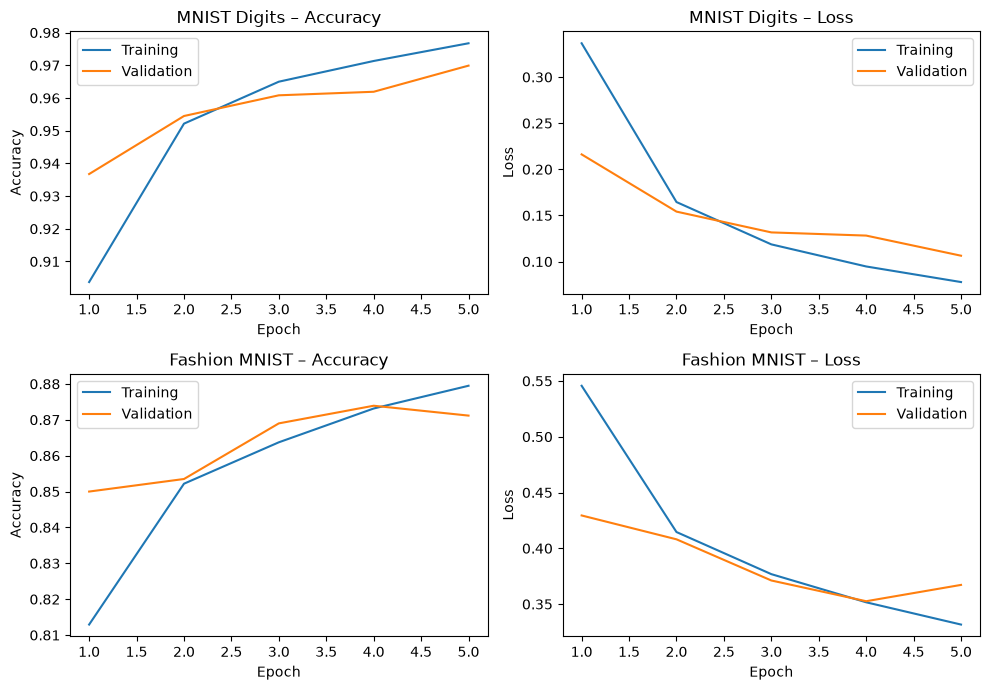

,Training Accuracy,Validation Accuracy
MNIST Digits,0.9768,0.9699
Fashion MNIST,0.8795,0.8712


In [ ]:
# plot taining and validation accuracy together
# plot training and validation loss together
# report final training and validation accuracy

histories = {"MNIST Digits": digits_history, "Fashion MNIST": fashion_history}

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for row, (name, hist) in enumerate(histories.items()):
    h = hist.history
    epochs = range(1, len(h["accuracy"]) + 1)

    axes[row, 0].plot(epochs, h["accuracy"], label="Training")
    axes[row, 0].plot(epochs, h["val_accuracy"], label="Validation")
    axes[row, 0].set_title(f"{name} – Accuracy")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Accuracy")
    axes[row, 0].legend()

    axes[row, 1].plot(epochs, h["loss"], label="Training")
    axes[row, 1].plot(epochs, h["val_loss"], label="Validation")
    axes[row, 1].set_title(f"{name} – Loss")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].set_ylabel("Loss")
    axes[row, 1].legend()

plt.tight_layout()
plt.show()

# Final training and validation accuracy
final_acc = pd.DataFrame({
    "Training Accuracy":   [h.history["accuracy"][-1] for h in histories.values()],
    "Validation Accuracy": [h.history["val_accuracy"][-1] for h in histories.values()],
}, index=histories.keys()).round(4)

display(final_acc)

## d) Compare Models

For each dataset, we train the same model for three different configurations:
- `(64, ReLU)`
- `(128, ReLU)`
- `(64, tanh)`

In [19]:
datasets = {
    "MNIST Digits":  (x_digits_fit, y_digits_fit, x_digits_val, y_digits_val),
    "Fashion MNIST": (x_fashion_fit, y_fashion_fit, x_fashion_val, y_fashion_val)}

configs = [(64, "relu"), (128, "relu"), (64, "tanh")]

# Reuse the part (c) results for the first configuration
config_histories = {
    ("MNIST Digits", 64, "relu"):  digits_history,
    ("Fashion MNIST", 64, "relu"): fashion_history}

for name, (x_fit, y_fit, x_val, y_val) in datasets.items():
    for units, act in configs[1:]:  # skip (64, relu) since part (c) already trained
        tf.keras.utils.set_random_seed(42)
        model = build_simple_model(hidden_units=units, activation=act)
        config_histories[(name, units, act)] = train_simple_model(model, x_fit, y_fit, x_val, y_val)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9201 - loss: 0.2808 - val_accuracy: 0.9534 - val_loss: 0.1599
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.9631 - loss: 0.1240 - val_accuracy: 0.9643 - val_loss: 0.1200
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9745 - loss: 0.0835 - val_accuracy: 0.9678 - val_loss: 0.1060
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9827 - loss: 0.0603 - val_accuracy: 0.9703 - val_loss: 0.1033
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9877 - loss: 0.0446 - val_accuracy: 0.9714 - val_loss: 0.1029
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9046 - loss: 0.3419 - val_accuracy: 0.9382 - val_loss: 0.2146
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9488 - loss: 0.1768 - val_accuracy: 0.9517 - val_loss: 0.1672
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9628 - loss: 0.1302 - v

In [21]:
config_results = pd.DataFrame([
    {
        "Dataset": name,
        "Hidden Units": units,
        "Activation": act,
        "Training Accuracy": config_histories[(name, units, act)].history["accuracy"][-1],
        "Validation Accuracy": config_histories[(name, units, act)].history["val_accuracy"][-1],
    }
    for name in datasets
    for units, act in configs
]).round(4)

display(config_results)

,Dataset,Hidden Units,Activation,Training Accuracy,Validation Accuracy
0,MNIST Digits,64,relu,0.9768,0.9699
1,MNIST Digits,128,relu,0.9877,0.9714
2,MNIST Digits,64,tanh,0.9775,0.9641
3,Fashion MNIST,64,relu,0.8795,0.8712
4,Fashion MNIST,128,relu,0.8887,0.8860
5,Fashion MNIST,64,tanh,0.8867,0.8797


For each dataset, we select the configuration with the highest final validation accuracy. For the MNIST Digits dataset, the best model is `(128, ReLU)`. For the Fashion MNIST, the best model is also `(128, ReLU)`. 

In [22]:
digits_best_model  = config_histories[("MNIST Digits", 128, "relu")].model
fashion_best_model = config_histories[("Fashion MNIST", 128, "relu")].model

We evaluate the trained model one on its test set and report test loss and accuracy.

In [23]:
digits_test_loss, digits_test_acc = digits_best_model.evaluate(x_digits_test, y_digits_test, verbose=0)
fashion_test_loss, fashion_test_acc = fashion_best_model.evaluate(x_fashion_test, y_fashion_test, verbose=0)

In [24]:
test_results = pd.DataFrame({
    "Test Loss":     [digits_test_loss, fashion_test_loss],
    "Test Accuracy": [digits_test_acc, fashion_test_acc],
}, index=["MNIST Digits", "Fashion MNIST"]).round(4)

display(test_results)

,Test Loss,Test Accuracy
MNIST Digits,0.0836,0.9733
Fashion MNIST,0.3604,0.8720
